# 09 · Física e investigación espacial

Desde deducir ecuaciones hasta simular órbitas, Python cubre todo el ciclo de la ciencia física: **SymPy** hace
el álgebra, **SciPy** resuelve lo que no tiene solución cerrada, **NumPy** analiza señales y **Astropy**, la
biblioteca comunitaria de la astronomía, mantiene correctas las unidades y las constantes.

**Aprenderás**
1. Matemáticas simbólicas: deducir la ecuación de movimiento de un péndulo con SymPy
2. Simulación numérica: resolverla con SciPy y ver dónde falla la aproximación de los libros de texto
3. Análisis de señales: recuperar la frecuencia de un péndulo con la transformada de Fourier
4. Unidades y constantes con Astropy, y la tercera ley de Kepler comprobada con los planetas reales
5. Integrar una órbita y validarla con la conservación de la energía y del momento angular
6. Coordenadas celestes: convertir entre sistemas de referencia

## 1. Deducir la ecuación de movimiento de forma simbólica
Para un péndulo de longitud $L$, el lagrangiano es la energía cinética menos la potencial,
$\mathcal{L} = \tfrac12 m L^2 \dot\theta^2 + m g L \cos\theta$. La ecuación de Euler-Lagrange da el movimiento;
SymPy hace el cálculo.

In [1]:
import sympy as sp

t = sp.symbols("t")
m, g, L = sp.symbols("m g L", positive=True)
theta = sp.Function("theta")(t)
lagrangian = sp.Rational(1, 2) * m * L**2 * theta.diff(t)**2 + m * g * L * sp.cos(theta)
euler_lagrange = sp.diff(lagrangian.diff(theta.diff(t)), t) - lagrangian.diff(theta)
eq = sp.Eq(sp.solve(euler_lagrange, theta.diff(t, 2))[0], theta.diff(t, 2))
eq

Eq(-g*sin(theta(t))/L, Derivative(theta(t), (t, 2)))

In [2]:
# for small angles sin(θ) ≈ θ and the equation has a closed-form solution with period 2π√(L/g)
theta0 = sp.symbols("theta0")
small = sp.dsolve(theta.diff(t, 2) + g / L * theta, theta, ics={theta.subs(t, 0): theta0, theta.diff(t).subs(t, 0): 0})
print(small)
print("periodo con ángulos pequeños:", sp.simplify(2 * sp.pi / sp.sqrt(g / L)))

Eq(theta(t), theta0*cos(sqrt(g)*t/sqrt(L)))
periodo con ángulos pequeños: 2*pi*sqrt(L)/sqrt(g)


## 2. Simular el péndulo completo
La ecuación real $\ddot\theta = -\tfrac{g}{L}\sin\theta$ no tiene solución elemental. `scipy.integrate.solve_ivp`
la integra numéricamente. Compararla con la fórmula de ángulos pequeños muestra cuándo basta la aproximación de
los libros de texto.

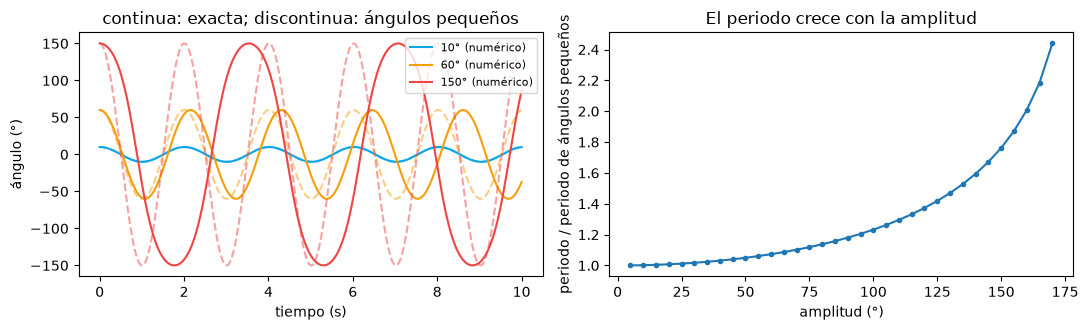

error del periodo de ángulos pequeños: 0.19% a 10°, 7.3% a 60°


In [3]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

G, LEN = 9.81, 1.0
def pendulum(t, y):
    th, om = y
    return [om, -G / LEN * np.sin(th)]

t_eval = np.linspace(0, 10, 4000)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for amp_deg, color in [(10, "#0ea5e9"), (60, "#f59e0b"), (150, "#ef4444")]:
    amp = np.radians(amp_deg)
    sol = solve_ivp(pendulum, (0, 10), [amp, 0], t_eval=t_eval, rtol=1e-9, atol=1e-9)
    ax[0].plot(sol.t, np.degrees(sol.y[0]), color=color, label=f"{amp_deg}° (numérico)")
    ax[0].plot(t_eval, amp_deg * np.cos(np.sqrt(G / LEN) * t_eval), "--", color=color, alpha=.5)
ax[0].set_xlabel("tiempo (s)"); ax[0].set_ylabel("ángulo (°)"); ax[0].legend(fontsize=8); ax[0].set_title("continua: exacta; discontinua: ángulos pequeños")

# period as a function of amplitude, measured from the simulation
amps = np.radians(np.linspace(5, 170, 34))
def period(amp):
    s = solve_ivp(pendulum, (0, 20), [amp, 0], events=lambda t, y: y[1], rtol=1e-10, atol=1e-10, dense_output=True)
    crossings = [tc for tc in s.t_events[0] if tc > 1e-6]
    return 2 * crossings[0]              # la velocidad es cero en cada punto de retorno, separados medio periodo
T0 = 2 * np.pi * np.sqrt(LEN / G)
ax[1].plot(np.degrees(amps), [period(a) / T0 for a in amps], "o-", ms=3)
ax[1].set_xlabel("amplitud (°)"); ax[1].set_ylabel("periodo / periodo de ángulos pequeños"); ax[1].set_title("El periodo crece con la amplitud")
plt.tight_layout(); plt.show()
print(f"error del periodo de ángulos pequeños: {100 * (period(np.radians(10)) / T0 - 1):.2f}% a 10°, "
      f"{100 * (period(np.radians(60)) / T0 - 1):.1f}% a 60°")

## 3. Encontrar la frecuencia con una transformada de Fourier
Los experimentos dan medidas con ruido, no ecuaciones. La transformada rápida de Fourier (FFT) encuentra la
frecuencia dominante de una señal ruidosa.

frecuencia dominante 0.4833 Hz -> periodo 2.069 s (simulación: 2.041 s)
resolución en frecuencia de una grabación de 60 s: 0.0167 Hz, así que la estimación es exacta dentro de un intervalo de frecuencia; graba más tiempo para afinar más


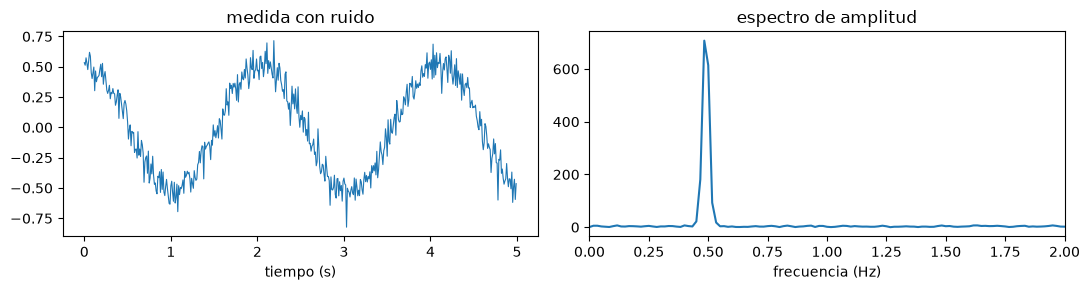

In [4]:
rng = np.random.default_rng(0)
amp = np.radians(30)
fs, duration = 100, 60                            # 100 muestras por segundo, un minuto
tt = np.arange(0, duration, 1 / fs)
signal = solve_ivp(pendulum, (0, duration), [amp, 0], t_eval=tt, rtol=1e-9).y[0]
measured = signal + rng.normal(0, 0.08, tt.size)   # ruido del sensor

spectrum = np.abs(np.fft.rfft(measured * np.hanning(tt.size)))
freqs = np.fft.rfftfreq(tt.size, 1 / fs)
f_peak = freqs[np.argmax(spectrum[1:]) + 1]
print(f"frecuencia dominante {f_peak:.4f} Hz -> periodo {1 / f_peak:.3f} s (simulación: {period(amp):.3f} s)")
print(f"resolución en frecuencia de una grabación de {duration} s: {1 / duration:.4f} Hz, así que la estimación es exacta "
      "dentro de un intervalo de frecuencia; graba más tiempo para afinar más")

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(tt[:500], measured[:500], lw=.8); ax[0].set_xlabel("tiempo (s)"); ax[0].set_title("medida con ruido")
ax[1].plot(freqs, spectrum); ax[1].set_xlim(0, 2); ax[1].set_xlabel("frecuencia (Hz)"); ax[1].set_title("espectro de amplitud")
plt.tight_layout(); plt.show()

## 4. Unidades, constantes y la tercera ley de Kepler con Astropy
Los errores de unidades han destruido naves espaciales. Astropy asocia unidades a los números, los convierte y
se niega a sumar magnitudes incompatibles. La tercera ley de Kepler dice que $T^2 = \frac{4\pi^2}{G M_\odot} a^3$:
el cuadrado del periodo orbital de un planeta crece con el cubo de su distancia al Sol.

In [5]:
import astropy.units as u
from astropy import constants as const

print(const.G, "\n", const.M_sun, "\n", (1 * u.au).to(u.km), "|", (1 * u.lyr).to(u.au))
try:
    1 * u.m + 1 * u.s
except u.UnitConversionError as e:
    print("rechazado:", e)

# semi-major axes (AU) and observed sidereal orbital periods (days)
planets = {"Mercury": (0.3871, 87.969), "Venus": (0.7233, 224.701), "Earth": (1.0000, 365.256),
           "Mars": (1.5237, 686.980), "Jupiter": (5.2034, 4332.59), "Saturn": (9.5371, 10759.22),
           "Uranus": (19.191, 30688.5), "Neptune": (30.069, 60182.0)}
print(f"\n{'planeta':<9}{'observado (a)':>14}{'Kepler (a)':>13}{'error':>9}")
for name, (a_au, t_days) in planets.items():
    predicted = (2 * np.pi * np.sqrt((a_au * u.au) ** 3 / (const.G * const.M_sun))).to(u.yr)
    observed = (t_days * u.day).to(u.yr)
    print(f"{name:<9}{observed.value:>14.3f}{predicted.value:>13.3f}{100 * (predicted / observed - 1).value:>8.2f}%")

  Name   = Gravitational constant
  Value  = 6.6743e-11
  Uncertainty  = 1.5e-15
  Unit  = m3 / (kg s2)
  Reference = CODATA 2022 
   Name   = Solar mass
  Value  = 1.988409870698051e+30
  Uncertainty  = 4.468805426856864e+25
  Unit  = kg
  Reference = IAU 2015 Resolution B 3 + CODATA 2022 
 149597870.7 km | 63241.07708426628 AU
rechazado: Can only apply 'add' function to quantities with compatible dimensions

planeta   observado (a)   Kepler (a)    error
Mercury           0.241        0.241    0.00%
Venus             0.615        0.615   -0.01%
Earth             1.000        1.000    0.00%
Mars              1.881        1.881    0.00%
Jupiter          11.862       11.870    0.06%
Saturn           29.457       29.453   -0.01%
Uranus           84.021       84.073    0.06%
Neptune         164.769      164.887    0.07%


## 5. Integrar una órbita y comprobarla con leyes de conservación
Lanzamos un satélite a una órbita elíptica alrededor de la Tierra e integramos la ley de la gravitación de
Newton. Una solución numérica solo es fiable si respeta la física: la **energía** y el **momento angular**
deben mantenerse constantes. Comparar una integración descuidada con una precisa muestra por qué importan las
tolerancias.

rtol=0.001: 56 pasos, deriva relativa de la energía 2.5e-02, deriva del momento angular 1.1e-02


rtol=1e-10: 1093 pasos, deriva relativa de la energía 7.8e-10, deriva del momento angular 3.0e-10
tras un día, la integración poco precisa sitúa el satélite a 3,834 km de donde realmente está


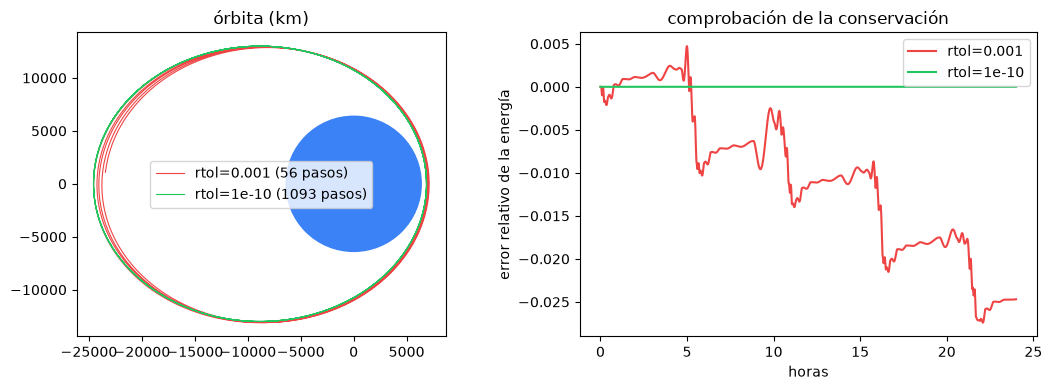

In [6]:
mu = (const.G * const.M_earth).to(u.km**3 / u.s**2).value      # parámetro gravitatorio de la Tierra, km^3/s^2
r0 = 6378 + 500                                                  # 500 km de altitud, en km
v_circ = np.sqrt(mu / r0)
state0 = [r0, 0, 0, 1.25 * v_circ]                               # un 25% más rápido que la circular: una elipse

def two_body(t, s):
    x, y, vx, vy = s
    r3 = (x * x + y * y) ** 1.5
    return [vx, vy, -mu * x / r3, -mu * y / r3]

T_orbit = 24 * 3600                                               # un día, unas 4,4 órbitas
tt = np.linspace(0, T_orbit, 4000)
def run(rtol):
    sol = solve_ivp(two_body, (0, T_orbit), state0, rtol=rtol, atol=min(rtol * 1e-3, 1e-6), dense_output=True)
    x, y, vx, vy = sol.sol(tt)                                    # evaluar la solución en una malla fina
    energy = 0.5 * (vx**2 + vy**2) - mu / np.hypot(x, y)
    h = x * vy - y * vx
    return sol, (x, y), energy, h

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
final = {}
for rtol, color in [(1e-3, "#ef4444"), (1e-10, "#22c55e")]:
    sol, (x, y), energy, h = run(rtol)
    final[rtol] = np.array([x[-1], y[-1]])
    ax[0].plot(x, y, color=color, lw=.8, label=f"rtol={rtol:g} ({sol.t.size} pasos)")
    ax[1].plot(tt / 3600, (energy - energy[0]) / abs(energy[0]), color=color, label=f"rtol={rtol:g}")
    print(f"rtol={rtol:g}: {sol.t.size} pasos, deriva relativa de la energía {abs(energy[-1] / energy[0] - 1):.1e}, "
          f"deriva del momento angular {abs(h[-1] / h[0] - 1):.1e}")
print(f"tras un día, la integración poco precisa sitúa el satélite a {np.linalg.norm(final[1e-3] - final[1e-10]):,.0f} km "
      "de donde realmente está")
ax[0].add_patch(plt.Circle((0, 0), 6378, color="#3b82f6")); ax[0].set_aspect("equal"); ax[0].legend(); ax[0].set_title("órbita (km)")
ax[1].set_xlabel("horas"); ax[1].set_ylabel("error relativo de la energía"); ax[1].legend(); ax[1].set_title("comprobación de la conservación")
plt.tight_layout(); plt.show()

## 6. Coordenadas celestes
Los astrónomos describen posiciones en distintos sistemas de referencia: ecuatorial (ascensión recta,
declinación), galáctico, eclíptico. Astropy convierte entre ellos.

In [7]:
from astropy.coordinates import SkyCoord

targets = {"Sirius": ("06h45m08.9s", "-16d42m58s"), "Betelgeuse": ("05h55m10.3s", "+07d24m25s"),
           "Galaxia de Andrómeda (M31)": ("00h42m44.3s", "+41d16m09s")}
for name, (ra, dec) in targets.items():
    c = SkyCoord(ra, dec, frame="icrs")
    gal = c.galactic
    print(f"{name:<24} RA {c.ra.deg:7.2f}°  Dec {c.dec.deg:6.2f}°  ->  galactic l {gal.l.deg:7.2f}°  b {gal.b.deg:6.2f}°")
sirius, betel = SkyCoord(*targets["Sirius"]), SkyCoord(*targets["Betelgeuse"])
print("separación angular Sirius-Betelgeuse:", sirius.separation(betel).to_string(unit=u.deg, precision=1))

Sirius                   RA  101.29°  Dec -16.72°  ->  galactic l  227.23°  b  -8.89°
Betelgeuse               RA   88.79°  Dec   7.41°  ->  galactic l  199.79°  b  -8.96°
Galaxia de Andrómeda (M31) RA   10.68°  Dec  41.27°  ->  galactic l  121.17°  b -21.57°
separación angular Sirius-Betelgeuse: 27d06m15.8s


## Bibliotecas que conviene conocer
| Área | Bibliotecas |
|---|---|
| matemáticas simbólicas | SymPy |
| simulación, EDO, optimización | SciPy, JAX (simulación diferenciable) |
| astronomía | Astropy, astroquery (consultas a archivos), Skyfield (efemérides precisas), poliastro/hapsira (astrodinámica), lightkurve (curvas de luz de Kepler/TESS) |
| física de partículas y nuclear | uproot, awkward-array, scikit-hep |
| fluidos, elementos finitos | FEniCS, PyClaw |
| computación cuántica | Qiskit, Cirq, PennyLane |

## Ejercicios
1. Añade resistencia del aire (un término $-c\,\dot\theta$) al péndulo y mide cómo decae la amplitud.
2. Aumenta la velocidad de lanzamiento a 1,45 veces la circular. ¿Sigue siendo una órbita ligada? Mira el signo de la energía.
3. Usa la tabla de planetas para ajustar $\log T$ frente a $\log a$ con NumPy y recuperar el exponente 3/2.